# Logistic model comparisons
This notebook only displays saved results. Run `python Notebooks/Models/training/train_lr_models.py` from the repository root to train and export, or add `--reports-only` to refresh reports without retraining.

Train-only models have train, validation, and test reports. Train+validation models have **one combined training report** and a test report. Their former validation rows are part of training, not a separate evaluation.

Parlay accuracy is a **percentage of winning settled tickets among tickets with positive stakes**, using the shared Kelly simulator and current market-specific betting parameters. Refunded tickets are excluded; each ticket counts once, not once per leg. Other metrics use fractions. Mean calibration error is the unweighted mean absolute gap across nonempty bins; expected calibration error is weighted by bin counts. Calibration curves use red-win probability and ten equal-width bins.


In [2]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from ufc_betting.config import settings
results_dir = settings.data_dir / 'model_comparisons' / 'lr_open_close'


## Train-only model: training

### Regularized

accuracy  parlay_accuracy_pct      f1   brier  \
model  odds                                                    
close1 close1    0.6552              44.5676  0.7144  0.2131   
close2 close2    0.6557              43.4343  0.7148  0.2133   
open   close1    0.6600              44.4219  0.7181  0.2134   
       close2    0.6605              43.5039  0.7183  0.2136   
       open      0.6502              48.3431  0.7133  0.2164   

               expected_calibration_error  mean_calibration_error  
model  odds                                                        
close1 close1                      0.0199                  0.0297  
close2 close2                      0.0178                  0.0278  
open   close1                      0.0095                  0.0266  
       close2                      0.0076                  0.0247  
       open                        0.0167                  0.1097

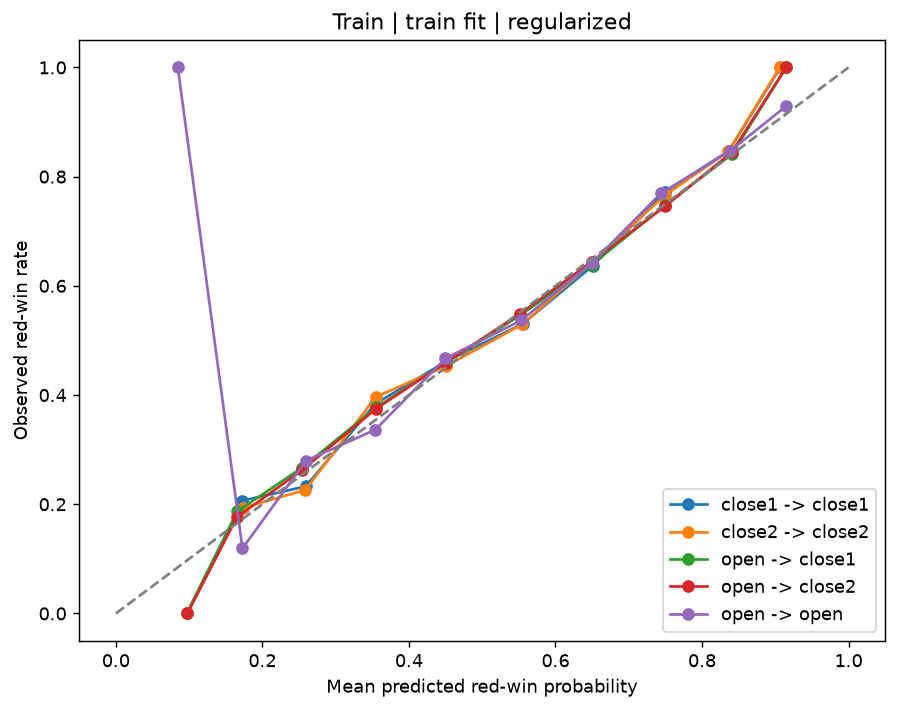

In [3]:
table = pd.read_csv(results_dir / 'train_train_regularized_metrics.csv', index_col=['model', 'odds'])
display(table.round(4))
display(Image(filename=str(results_dir / 'plots' / 'train_train_regularized_calibration.png')))


### Inference

accuracy  parlay_accuracy_pct      f1   brier  expected_calibration_error  mean_calibration_error
model  odds                                                                                                     
close1 close1    0.6590              46.8750  0.7175  0.2130                      0.0161                  0.1118
close2 close2    0.6587              43.5743  0.7176  0.2131                      0.0148                  0.1126
open   close1    0.6590              44.9304  0.7168  0.2135                      0.0155                  0.0401
       close2    0.6597              44.0313  0.7178  0.2136                      0.0133                  0.0405
       open      0.6520              47.2868  0.7145  0.2162                      0.0198                  0.1105

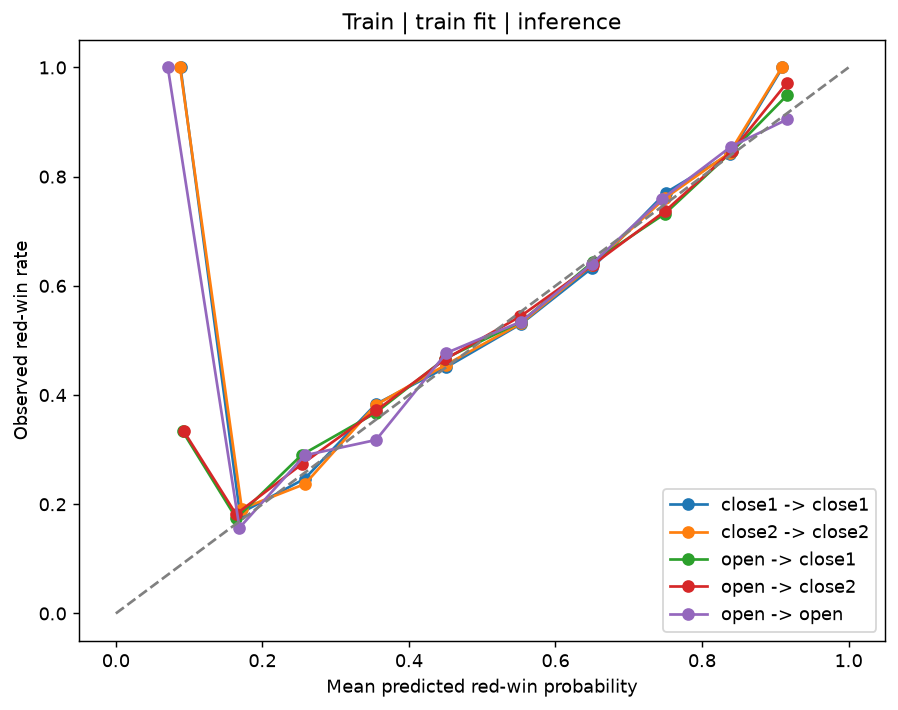

In [3]:
table = pd.read_csv(results_dir / 'train_train_inference_metrics.csv', index_col=['model', 'odds'])
display(table.round(4))
display(Image(filename=str(results_dir / 'plots' / 'train_train_inference_calibration.png')))


## Train-only model: held-out validation

### Regularized

accuracy  parlay_accuracy_pct      f1   brier  expected_calibration_error  mean_calibration_error
model  odds                                                                                                     
close1 close1    0.7123              54.6875  0.7450  0.1953                      0.0457                  0.0512
close2 close2    0.7123              52.8571  0.7450  0.1954                      0.0375                  0.0510
open   close1    0.7123              58.5714  0.7463  0.1950                      0.0461                  0.0473
       close2    0.7123              48.5714  0.7457  0.1952                      0.0461                  0.0454
       open      0.7048              55.7143  0.7351  0.2001                      0.0349                  0.0444

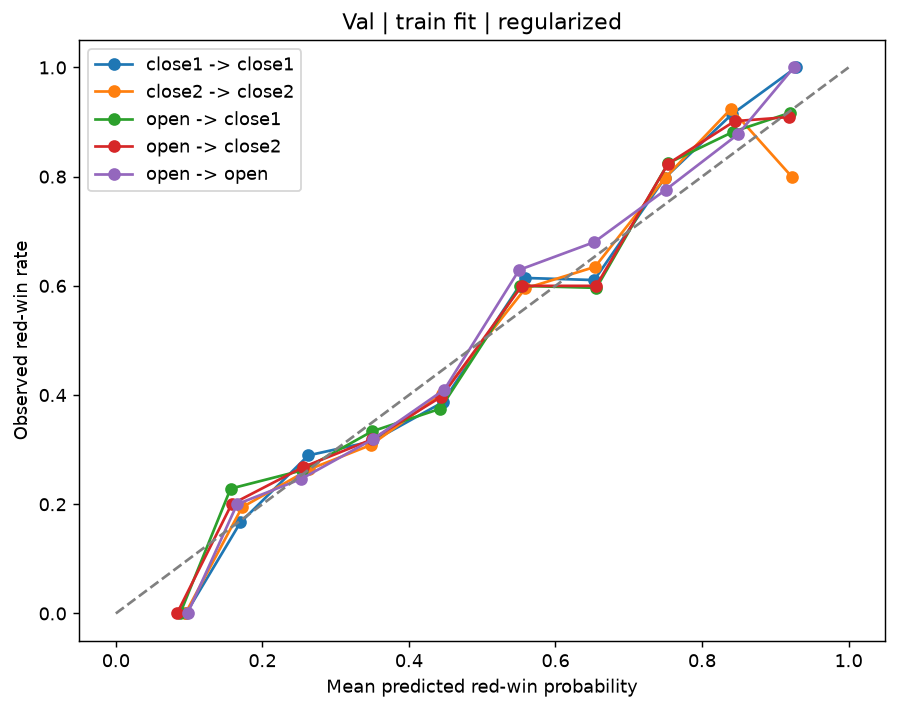

In [4]:
table = pd.read_csv(results_dir / 'train_val_regularized_metrics.csv', index_col=['model', 'odds'])
display(table.round(4))
display(Image(filename=str(results_dir / 'plots' / 'train_val_regularized_calibration.png')))


### Inference

accuracy  parlay_accuracy_pct      f1   brier  expected_calibration_error  mean_calibration_error
model  odds                                                                                                     
close1 close1    0.7108              61.1940  0.7440  0.1951                      0.0372                  0.0420
close2 close2    0.7108              55.0725  0.7440  0.1952                      0.0376                  0.0488
open   close1    0.7093              58.5714  0.7437  0.1950                      0.0479                  0.0482
       close2    0.7108              50.7042  0.7440  0.1951                      0.0449                  0.0489
       open      0.7139              57.7465  0.7439  0.1999                      0.0476                  0.0502

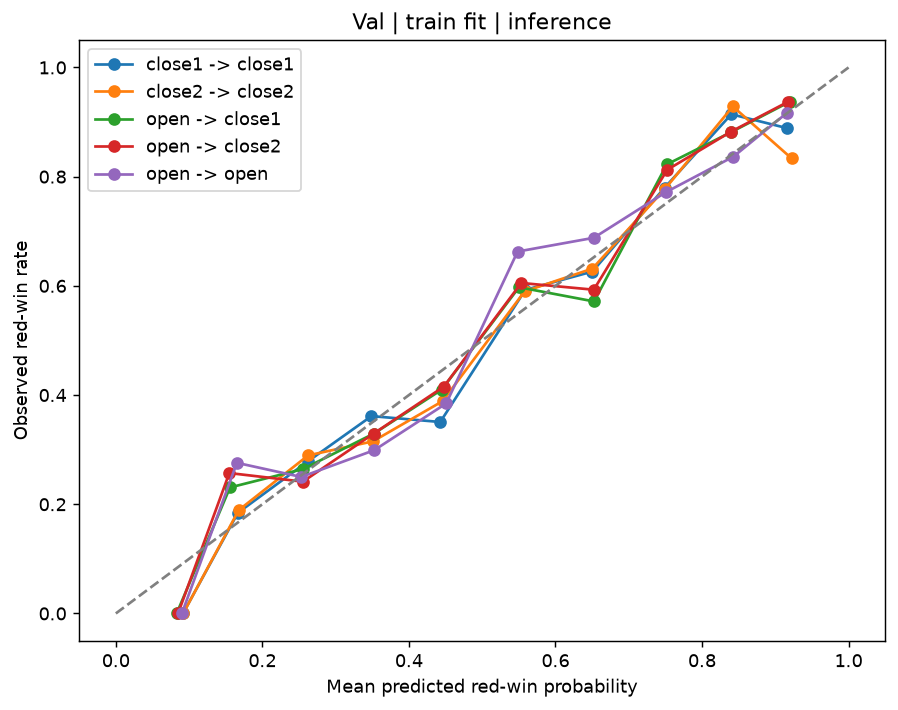

In [5]:
table = pd.read_csv(results_dir / 'train_val_inference_metrics.csv', index_col=['model', 'odds'])
display(table.round(4))
display(Image(filename=str(results_dir / 'plots' / 'train_val_inference_calibration.png')))


## Train+validation model: combined training

### Regularized

accuracy  parlay_accuracy_pct      f1   brier  expected_calibration_error  mean_calibration_error
model  odds                                                                                                     
close1 close1    0.6672              47.9279  0.7219  0.2103                      0.0148                  0.0291
close2 close2    0.6675              46.6321  0.7218  0.2105                      0.0148                  0.0301
open   close1    0.6657              46.2069  0.7199  0.2107                      0.0153                  0.0253
       close2    0.6657              44.2177  0.7199  0.2109                      0.0142                  0.0256
       open      0.6604              44.8980  0.7185  0.2137                      0.0133                  0.0357

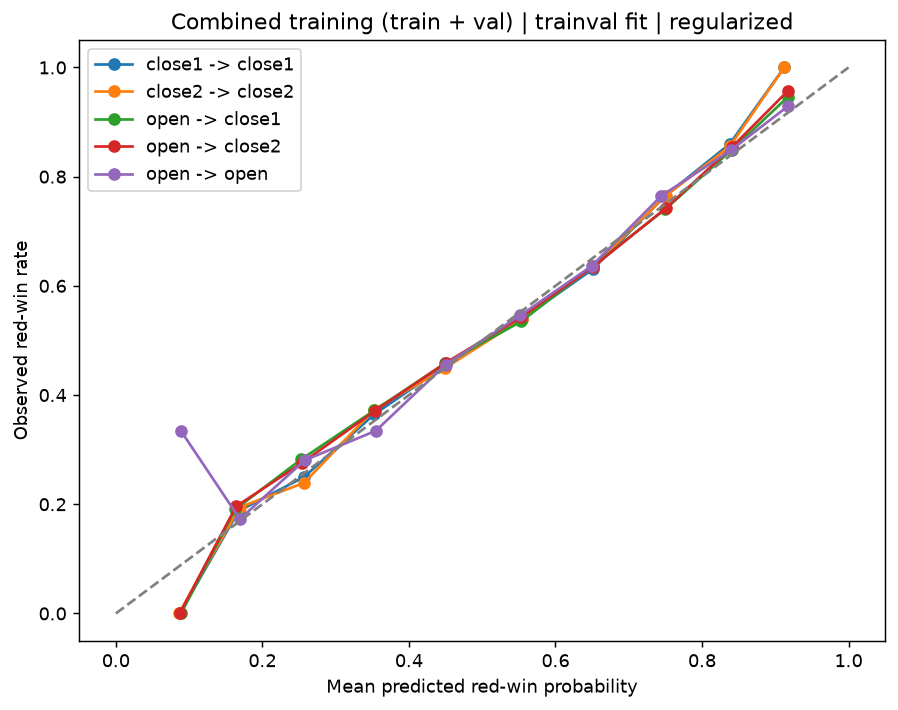

In [8]:
table = pd.read_csv(results_dir / 'trainval_train_regularized_metrics.csv', index_col=['model', 'odds'])
display(table.round(4))
display(Image(filename=str(results_dir / 'plots' / 'trainval_train_regularized_calibration.png')))


### Inference

accuracy  parlay_accuracy_pct      f1   brier  expected_calibration_error  mean_calibration_error
model  odds                                                                                                     
close1 close1    0.6681              49.0231  0.7226  0.2103                      0.0149                  0.0310
close2 close2    0.6675              45.8262  0.7222  0.2105                      0.0142                  0.0261
open   close1    0.6653              45.1115  0.7199  0.2108                      0.0180                  0.0253
       close2    0.6662              45.0085  0.7204  0.2109                      0.0157                  0.0244
       open      0.6617              42.5676  0.7194  0.2137                      0.0123                  0.0290

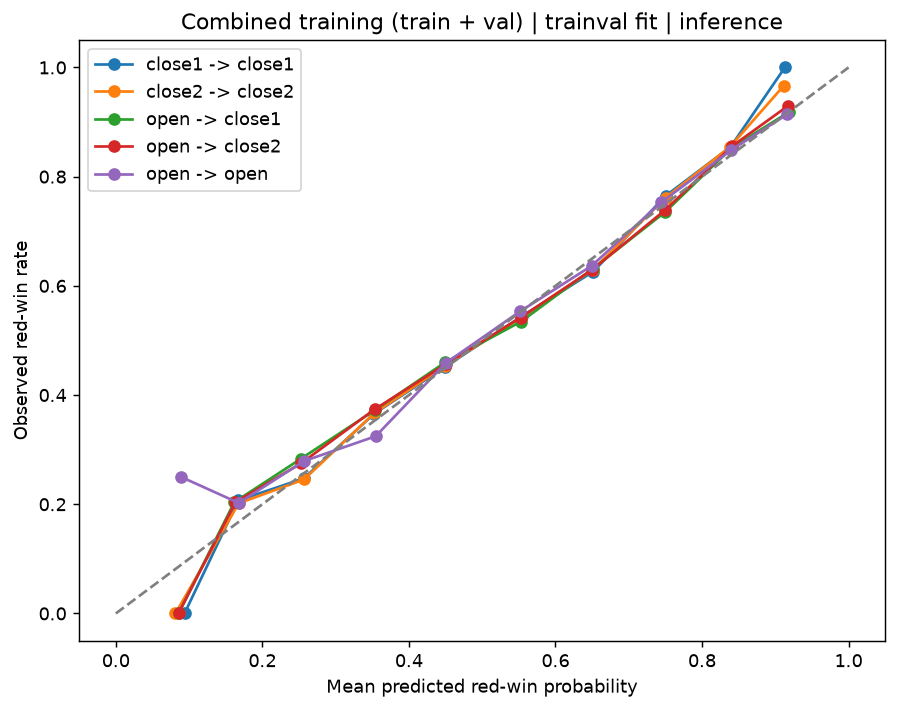

In [9]:
table = pd.read_csv(results_dir / 'trainval_train_inference_metrics.csv', index_col=['model', 'odds'])
display(table.round(4))
display(Image(filename=str(results_dir / 'plots' / 'trainval_train_inference_calibration.png')))


## Train+validation model: held-out test

### Regularized

accuracy  parlay_accuracy_pct      f1   brier  expected_calibration_error  mean_calibration_error
model  odds                                                                                                     
close1 close1    0.7045              43.3333  0.7529  0.2071                      0.0708                  0.0715
close2 close2    0.7010              50.0000  0.7521  0.2071                      0.0696                  0.0710
open   close1    0.7079              50.0000  0.7564  0.2071                      0.0854                  0.1778
       close2    0.7045              48.3871  0.7543  0.2070                      0.0912                  0.1696
       open      0.6907              45.1613  0.7429  0.2120                      0.0344                  0.0614

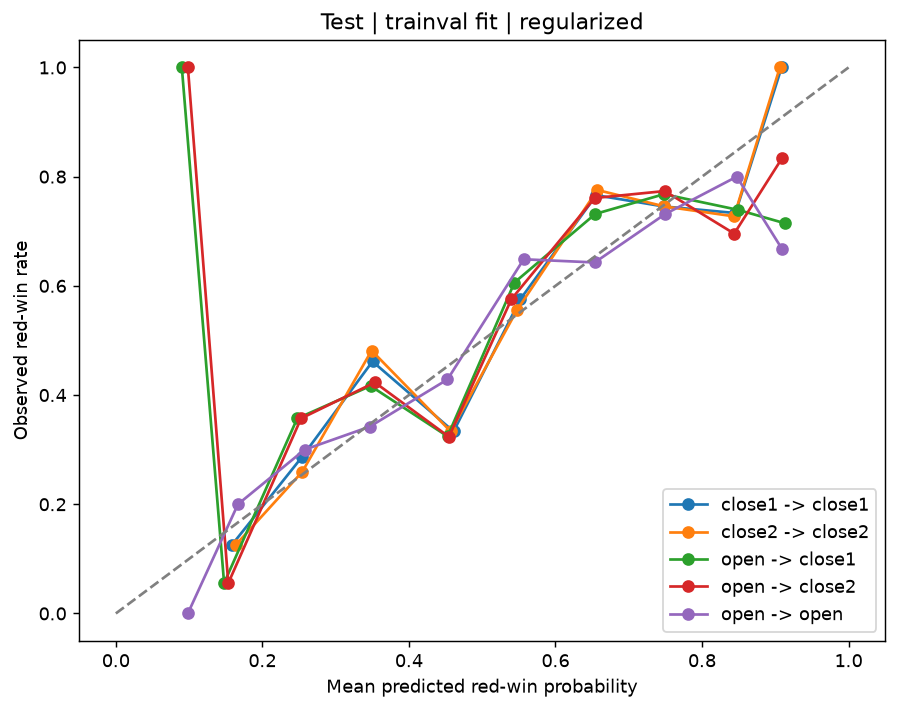

In [10]:
table = pd.read_csv(results_dir / 'trainval_test_regularized_metrics.csv', index_col=['model', 'odds'])
display(table.round(4))
display(Image(filename=str(results_dir / 'plots' / 'trainval_test_regularized_calibration.png')))


### Inference

accuracy  parlay_accuracy_pct      f1   brier  expected_calibration_error  mean_calibration_error
model  odds                                                                                                     
close1 close1    0.7045              46.6667  0.7529  0.2073                      0.0799                  0.1637
close2 close2    0.7010              48.3871  0.7507  0.2072                      0.0722                  0.0736
open   close1    0.7113              51.6129  0.7586  0.2073                      0.0913                  0.1785
       close2    0.7045              45.1613  0.7529  0.2072                      0.0881                  0.1653
       open      0.6838              45.1613  0.7386  0.2121                      0.0379                  0.0628

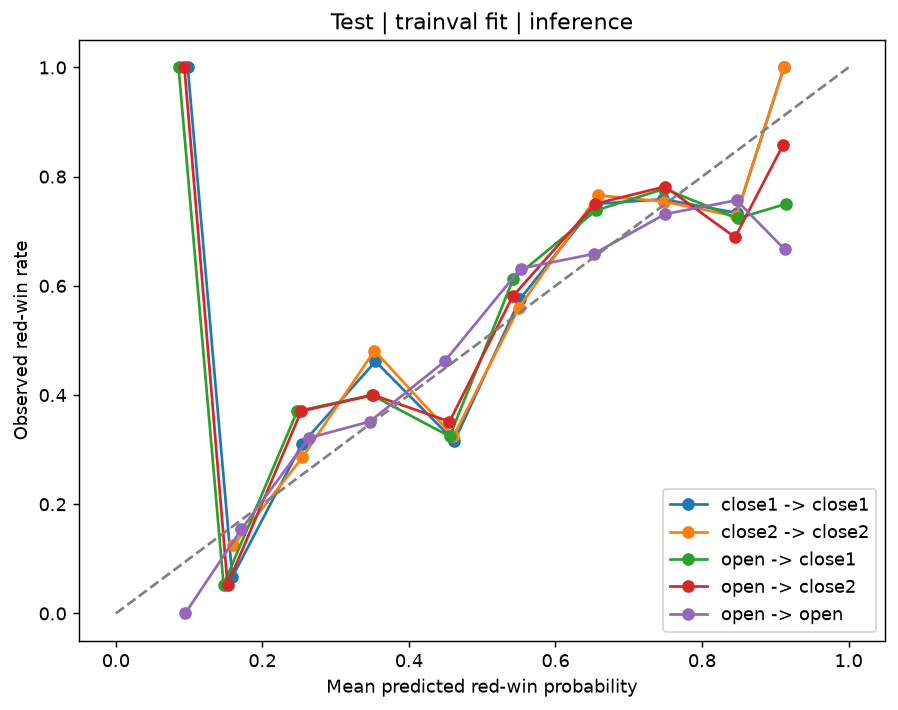

In [11]:
table = pd.read_csv(results_dir / 'trainval_test_inference_metrics.csv', index_col=['model', 'odds'])
display(table.round(4))
display(Image(filename=str(results_dir / 'plots' / 'trainval_test_inference_calibration.png')))
